Imports Necessary to run the Notebook

In [1]:
#libs needed for debugging
import os
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
import joblib
import warnings
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score
import string
from nltk.corpus import stopwords
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.preprocessing import label_binarize
from numpy import argmax
from lime import lime_text    
from sklearn.pipeline import make_pipeline
from lime.lime_text import LimeTextExplainer
import sklearn.cluster as clustering
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


We already loaded the data ,cleaned it and saved as a CSV file.
However you can run the following snippets of code to load and clean the data. The snippet with the exercices will allways use whats saved inside the Data_Set folder 

In [2]:


# Load the training data
df_train = pd.read_csv('Data_Set/train.csv', header=0)
df_train = df_train.reset_index()  # make sure indexes pair with number of rows


# Load the test data
df_test = pd.read_csv('Data_Set/test.csv', header=0)
df_test = df_test.reset_index()  # make sure indexes pair with number of rows

# Load the validation data
df_val = pd.read_csv('Data_Set/val.csv', header=0)
df_val = df_val.reset_index()  # make sure indexes pair with number of rows

We are going to clean the data and keep a data frame untouched and his cleaned version respectively

In [ ]:

#We found out that some texts are just "none" or an error string, so we remove them here
error_string = "service unavailable request due to maintenance downtime or capacity problems please try again later additionally service unavailable error was encountered while trying to use an errordocument to handle the request"

def clean_data(text,stops):
    text = text.lower()
    trans_table = str.maketrans({p: " " for p in string.punctuation})
    text = text.translate(trans_table)
    words = text.split()
    final = []
    #filter stopwords and words with digits
    final = [word for word in words if word not in stops and not any(char.isdigit() for char in word)]
    cleaned = " ".join(final)
    
    cleaned = " ".join(cleaned.split())  # normalize spaces
    return cleaned

"""
Clean the dataframe by removing stopwords, punctuation, digits and rows with "none" or error string
We create a new dataframe to avoid issues with iterrows and None values
We also create the non-cleaned dataframe to use later for KNN explanations (butt with the "none" and error rows removed)
"""
def clean_dataframe(df):
    
    #WARNINGS - base weekdays will not remove the word "feira" if it appears alone
    base_weekdays = [
        "segunda-feira", "segundafeira", "segunda", "terça-feira", "terçafeira", "terça", "quarta-feira", "quartafeira", 
        "quarta", "quinta-feira", "quintafeira", "quinta", "sexta-feira",
        "sextafeira", "sexta", "sábado", "domingo"
    ]
    meses_pt = [
        "janeiro",
        "fevereiro",
        "marco",
        "março",    # In case accents are used
        "abril",
        "maio",
        "junho",
        "julho",
        "agosto",
        "setembro",
        "outubro",
        "novembro",
        "dezembro"
    ]

    stops = stopwords.words("portuguese")
    stops.extend(base_weekdays)
    stops.extend(meses_pt)

    #Creating the new cleaned dataframe and the non-cleaned one
    cleaned_rows = []
    non_cleaned_rows = []
    for _, row in df.iterrows():
        
        cleaned_row= clean_data(row['Text'],stops)
        
        #depois colocar isto antes do cleaned_row = clean_data(row['Text'],stops)
        if cleaned_row == "none" or cleaned_row == error_string:
            continue
        non_cleaned_row = {}
        non_cleaned_row['Label'] = row['Label']
        non_cleaned_row['Text'] = row['Text']
        non_cleaned_rows.append(non_cleaned_row)
        
        new_row = {}
        new_row['Label'] = row['Label']
        new_row['Text'] = cleaned_row
        cleaned_rows.append(new_row)
    

    non_cleaned_df = pd.DataFrame(non_cleaned_rows).reset_index(drop=True)
    cleaned_df = pd.DataFrame(cleaned_rows).reset_index(drop=True)
    return cleaned_df, non_cleaned_df

df_train_cleaned, df_train_non_cleaned = clean_dataframe(df_train)

df_test_cleaned, df_test_non_cleaned = clean_dataframe(df_test)

df_val_cleaned, df_val_non_cleaned = clean_dataframe(df_val)

#Save it to csv files for future use
df_train_cleaned.to_csv('Data_Set/train_cleaned.csv', index=False)
df_test_cleaned.to_csv('Data_Set/test_cleaned.csv', index=False)
df_val_cleaned.to_csv('Data_Set/val_cleaned.csv', index=False)

df_test_non_cleaned.to_csv('Data_Set/test_non_cleaned.csv', index=False)
df_train_non_cleaned.to_csv('Data_Set/train_non_cleaned.csv', index=False)
df_val_non_cleaned.to_csv('Data_Set/val_non_cleaned.csv', index=False)
    

In [ ]:
#Examples of cleaned and non-cleaned data
print(df_train_cleaned.at[32875,'Text'])

print(df_train_non_cleaned.at[32875,'Text'])

print(df_train_cleaned.at[32875,'Label'])

Like the cleaning of the data, we will use the vectorizer in the joblib. You can always run this snippet to extract the TF-IDF features described in Exercise 1 a).

In [4]:
vectorizer = TfidfVectorizer( lowercase=True,
                              max_features=5000,
                              max_df = 0.9,
                              min_df= 10,
                              ngram_range= (1,3),
                              stop_words = "english",
                              use_idf=True,
                              smooth_idf=True
                            )

#Create the TF-IDF vectors for training and testing data (using the training data to fit the vectorizer)
training_vectors = vectorizer.fit_transform(df_train_cleaned['Text'])


#transform the vectorizer to a joblib file for future use
VEC_PATH = 'tfidf_vectorizer.joblib'
joblib.dump(vectorizer, VEC_PATH)

['tfidf_vectorizer.joblib']

The following cells are for the Exercise 1 b).
The models are already saved in the joblibs, but you can allways run theses cells to see for yourself (it does take a little bit of time). 


In [6]:



#We will use the vectorizer from the joblib file to create the TF-IDF vectors for the test data
vectorizer = joblib.load(VEC_PATH)

#vectorizer is already fitted with the training data, so we just transform the test data
X = vectorizer.transform(df_train_cleaned['Text'])
y = df_train_cleaned['Label'].values  

#defining cross-validation 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = 'f1_macro'
results_dir = 'cv_results'
os.makedirs(results_dir, exist_ok=True)

Here are the models and the HyperParameters that we used.

In [7]:
models = {
    'decision_tree': {
        'pipeline': Pipeline([('clf', DecisionTreeClassifier(random_state=42))]),
        'params': {
            'clf__criterion': ['gini', 'entropy'],
            'clf__max_depth': [None, 10, 20],
            'clf__min_samples_leaf': [1, 2, 5]
        }
    },
    'gaussian_nb': {
        # use SVD to reduce dimensionality and produce dense input for GaussianNB
        'pipeline': Pipeline([('svd', TruncatedSVD(n_components=200, random_state=42)),
                              ('clf', GaussianNB())]),
        'params': {
            'svd__n_components': [100, 200],
            'clf__var_smoothing': [1e-9, 1e-8]
        }
    },
    'logreg_l2': {
        'pipeline': Pipeline([('clf', LogisticRegression(penalty='l2', solver='saga', max_iter=2000, random_state=42))]),
        'params': {
            'clf__C': [0.01, 0.1, 1, 10],
            'clf__class_weight': [None, 'balanced']
        }
    },
    'logreg_l1': {
        'pipeline': Pipeline([('clf', LogisticRegression(penalty='l1', solver='saga', max_iter=2000, random_state=42))]),
        'params': {
            'clf__C': [0.01, 0.1, 1, 10],
            'clf__class_weight': [None, 'balanced']
        }
    },
    'mlp': {
        # SVD -> scaler -> MLP
        'pipeline': Pipeline([
            ('svd', TruncatedSVD(n_components=200, random_state=42)),
            ('scaler', StandardScaler()),
            ('clf', MLPClassifier(max_iter=800, random_state=42))
        ]),
        'params': {
            'svd__n_components': [100, 200],
            'clf__hidden_layer_sizes': [(50,), (100,), (50, 25), (100, 50)],
            'clf__alpha': [1e-4, 1e-3],
            'clf__learning_rate_init': [1e-3],
            'clf__activation': ['relu']
        }
    }
}

Training the models and Evaluating them using 5-fold cross-validation.
(WARNING: it takes 30 to 40 minutes)

In [8]:
# We used 5-fold cross-validation with GridSearchCV 
for name, spec in models.items():
    gs = GridSearchCV(spec['pipeline'], spec['params'],
                      cv=cv, scoring=scoring, n_jobs=-1, verbose=0, refit=True)
    gs.fit(X, y)
    # save results
    pd.DataFrame(gs.cv_results_).to_csv(os.path.join(results_dir, f"{name}_cv_results.csv"), index=False)
    joblib.dump(gs.best_estimator_, os.path.join(results_dir, f"{name}_best_estimator.joblib"))
    print(f"Saved cv_results and best_estimator for {name} in {results_dir}")

print("\nAll searches complete. Results directory:", results_dir)

Saved cv_results and best_estimator for decision_tree in cv_results
Saved cv_results and best_estimator for gaussian_nb in cv_results
Saved cv_results and best_estimator for logreg_l2 in cv_results
Saved cv_results and best_estimator for logreg_l1 in cv_results
Saved cv_results and best_estimator for mlp in cv_results

All searches complete. Results directory: cv_results


Auxiliary functions for computing metrics and plotting ROC/AUC (Exercise 1 b) and c) )

In [9]:
#Auxiliary functions for computing metrics and plotting ROC/AUC (Exercise 1 b) and c) )

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
RESULTS_DIR = "cv_results"
OUT_METRICS = os.path.join(RESULTS_DIR, "metrics_comparison.csv")
OUT_ROC = os.path.join(RESULTS_DIR, "best_model_roc.png")

def try_get_scores(est, X, y):
    # attempt predict_proba then decision_function; return None if not available
    try:
        probs = cross_val_predict(est, X, y, cv=CV, method='predict_proba', n_jobs=-1)
        return probs
    except Exception:
        try:
            scores = cross_val_predict(est, X, y, cv=CV, method='decision_function', n_jobs=-1)
            return scores
        except Exception:
            return None
        
def compute_metrics(estimators, X, y):
    rows = []
    scores_cache = {}
    for name, est in estimators.items():
        print(f"Evaluating: {name}")
        y_pred = cross_val_predict(est, X, y, cv=CV, n_jobs=-1)
        acc = accuracy_score(y, y_pred)
        prec = precision_score(y, y_pred, average='macro', zero_division=0)
        rec = recall_score(y, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y, y_pred, average='macro', zero_division=0)
        rows.append({
            'model': name,
            'accuracy': acc,
            'precision_macro': prec,
            'recall_macro': rec,
            'f1_macro': f1
        })
        scores = try_get_scores(est, X, y)
        if scores is not None:
            scores_cache[name] = scores
    dfm = pd.DataFrame(rows).sort_values(by='f1_macro', ascending=False).reset_index(drop=True)
    dfm.to_csv(OUT_METRICS, index=False)
    print(f"\nSaved metrics table to {OUT_METRICS}\n")
    print(dfm.to_string(index=False, float_format="%.4f"))
    return dfm, scores_cache

def plot_roc_for_best(dfm, scores_cache, y):
    best_name = dfm.loc[0, 'model']
    print(f"\nBest model by f1_macro: {best_name}")
    if best_name not in scores_cache:
        print("No probability/score available for best model; cannot plot ROC/AUC.")
        return
    y_score = scores_cache[best_name]
    classes = np.unique(y)
    n_classes = len(classes)
    plt.figure(figsize=(8,6))
    if n_classes == 2:
        # binary: ensure shape and get positive-class scores
        if y_score.ndim == 2 and y_score.shape[1] >= 2:
            prob_pos = y_score[:,1]
        else:
            prob_pos = y_score.ravel()
        fpr, tpr, _ = roc_curve(y, prob_pos, pos_label=classes[-1])
        auc_val = roc_auc_score(y, prob_pos)
        plt.plot(fpr, tpr, label=f'{best_name} (AUC = {auc_val:.4f})', lw=2)
    else:
        # multiclass: one-vs-rest per-class curves + macro AUC
        y_bin = label_binarize(y, classes=classes)
        aucs = []
        for i, cls in enumerate(classes):
            if y_score.ndim == 2 and y_score.shape[1] == n_classes:
                score_i = y_score[:, i]
            else:
                score_i = y_score.ravel()
            fpr, tpr, _ = roc_curve(y_bin[:, i], score_i)
            auc_i = roc_auc_score(y_bin[:, i], score_i)
            aucs.append(auc_i)
            plt.plot(fpr, tpr, lw=1, label=f'class {cls} (AUC={auc_i:.3f})')
        try:
            macro_auc = roc_auc_score(y_bin, y_score, average='macro', multi_class='ovr')
        except Exception:
            macro_auc = np.mean(aucs)
        plt.plot([], [], ' ', label=f'macro AUC = {macro_auc:.4f}')
    
    #AVISO - coloquei isto dentro da funçao - nao sei se esta certo
    plt.plot([0,1], [0,1], 'k--', alpha=0.5)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC curve — logreg_l12')
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.savefig(OUT_ROC)
    print(f"Saved ROC plot to {OUT_ROC}")
    plt.show()

We will get the best models saved in the joblibs and show their test metrics and plot the ROC curve for the best model

Evaluating: decision_tree
Evaluating: gaussian_nb
Evaluating: logreg_l2
Evaluating: logreg_l1
Evaluating: mlp

Saved metrics table to cv_results/metrics_comparison.csv

        model  accuracy  precision_macro  recall_macro  f1_macro
    logreg_l2    0.9002           0.9003        0.9002    0.9002
    logreg_l1    0.8959           0.8960        0.8959    0.8959
          mlp    0.8957           0.8957        0.8957    0.8957
decision_tree    0.8288           0.8290        0.8288    0.8287
  gaussian_nb    0.7346           0.7400        0.7344    0.7330

Best model by f1_macro: logreg_l2
Saved ROC plot to cv_results/best_model_roc.png


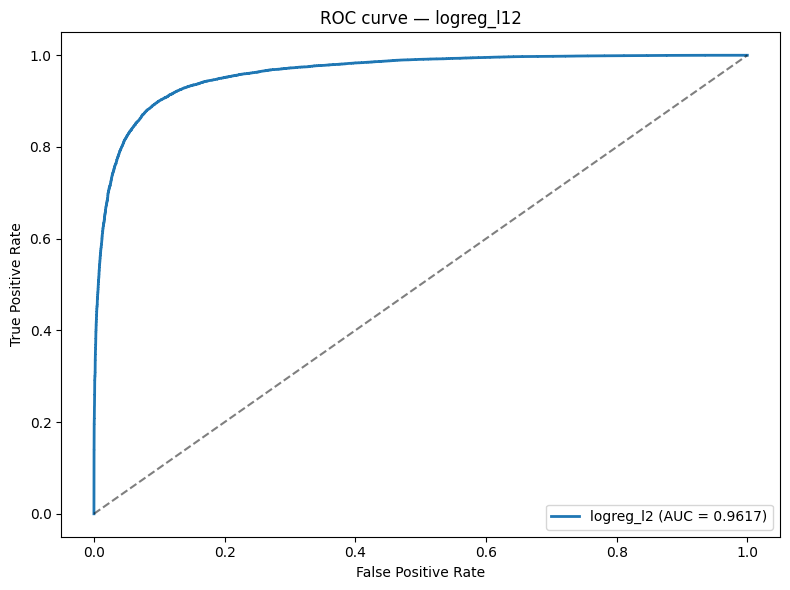

In [10]:
#load all the best models

#in case you did not run the cell with the models dictionary : ) 
models_names = ['decision_tree', 'gaussian_nb', 'logreg_l2', 'logreg_l1', 'mlp']

best_models = {}
for name in models_names:
    model_path = os.path.join(results_dir, f"{name}_best_estimator.joblib")
    best_models[name] = joblib.load(model_path)

    #show the classification report for each model 
   
    
    #ATUALMENTE ESTAMOS A USAR APENAS ESTA FUNCAO PARA OBTER AS METRICAS, MAS SE QUISERMOS TAMBEM PODEMOS DESCOMENTAR O CODIGO ABAIXO PARA MOSTRAR OS REPORTS
    #print(f"\n=== Classification Report for {name} on Training Data using 5-fold CV ===")
    #y_pred = cross_val_predict(best_models[name], X, y, cv=cv, n_jobs=-1)
    #print("classification report (cv):")
    #print(classification_report(y, y_pred, digits=4))
    
dfm, scores_cache = compute_metrics(best_models, X, y)
plot_roc_for_best(dfm, scores_cache, y)



Exercise 2 a)

In [ ]:
#2 a) 
best_model_path = "cv_results/logreg_l2_best_estimator.joblib" #REMOVER ESTA LINHA SE JA TIVER DEFINIDO ANTES
vectorizer = joblib.load(VEC_PATH)
feature_names = vectorizer.get_feature_names_out()


pipeline = joblib.load(best_model_path)
top_n=10

#Get the models from the pipelines to analyze the coefficients
best_model = pipeline.named_steps['clf']
coefs = best_model.coef_.ravel() #.ravel() para transformar numa array 1D porque a classificaçao é binaria
sorted_idx = np.argsort(coefs)
top_positive_idx = sorted_idx[-top_n:][::-1]
print(f"\nTop {top_n} real news words by absolute coefficient value:")
for idx in top_positive_idx:
    print(f"  {feature_names[idx]}: {coefs[idx]:.6f}") 

print(f"\nTop {top_n} real news words:")
top_negative_idx = sorted_idx[:top_n]
for idx in top_negative_idx:
    print(f"  {feature_names[idx]}: {coefs[idx]:.6f}")


Top 10 real news words by absolute coefficient value:
  feira: 14.408959
  sublinhou: 9.918930
  sic: 9.162891
  dia mundial: 8.342620
  inflação: 7.959629
  países baixos: 7.860219
  lamentou: 7.739331
  lusa: 7.092543
  estado norte: 7.046653
  realiza: 6.908664

Top 10 real news words:
  actual: -13.834596
  acção: -13.831723
  cm: -13.490136
  actividade: -13.373728
  actualmente: -11.969664
  projecto: -11.767840
  director: -11.684234
  directo: -11.347865
  direcção: -11.106354
  pois: -10.649594


AVISO: ISTO NAO É PARA FICAR NA ENTREGA FINAL-------------------------

TER EM CONTA O QUE É o SVD , SCALER e o CLF (classifier) para explicar no pdf

-----------------------------------------------------------------------------------

Exercise 2 b)

In [ ]:
#2 b)
model_l2_path = "cv_results/logreg_l2_best_estimator.joblib"
model_l1_path = "cv_results/logreg_l1_best_estimator.joblib"
pipeline_l2 = joblib.load(model_l2_path)
pipeline_l1 = joblib.load(model_l1_path)

#Get the models from the pipelines to analyze the coefficients
model_l2 = pipeline_l2.named_steps['clf']
model_l1 = pipeline_l1.named_steps['clf']
#Colocar na resposta os valores de non-zero features e corrigir esta resposta
"""How many features have non-zero weights in each?

L1 regularization (Lasso) produces sparse models: many coefficients are exactly zero.
L2 regularization (Ridge) produces dense models: most coefficients are non-zero (but may be small).
What does this tell you about feature selection?

L1 regularization selects features by setting many weights to zero, automatically choosing a subset of important words.
L2 regularization shrinks all weights but does not remove features.
When would you prefer L1 vs L2 for text classification?

L1: When you want automatic feature selection, a simpler model, or interpretability (see which words matter).
L2: When you expect many features to contribute a little, or want to avoid overfitting without removing features.
Summary:

L1 = feature selection, sparse model.
L2 = all features used, less interpretability.
Prefer L1 for high-dimensional, sparse data (like text) and interpretability; L2 for stability and when all features may matter."""

def get_nonzero_features(model):
    if not hasattr(model, 'coef_'):
        print("Model does not have coef_ attribute; cannot extract feature importances.")
        return
    coefs = model.coef_.ravel()
    nonzero_count = np.sum(coefs != 0)
    print(f"Number of non-zero features: {nonzero_count}")
    return nonzero_count


get_nonzero_features(model_l2)
get_nonzero_features(model_l1)

Number of non-zero features: 5000
Number of non-zero features: 2155


np.int64(2155)

In [33]:

# c) and d) 
def explain_with_lime_randomsamples(c, df, num_samples=1000):

    if num_samples == 0:
        return
    
    random_idxs = np.random.choice(len(df), size=num_samples, replace=False)

    correct_classifications = 0
    total_classifications = 0

    for idx in random_idxs:
        if argmax(c.predict_proba([df.loc[idx, 'Text']])) == df.loc[idx, 'Label']:
            correct_classifications += 1
        total_classifications += 1

    accuracy = correct_classifications / total_classifications
    print(f"\nLIME-based classification accuracy over {num_samples} random samples: {accuracy}")

def explain_with_lime(model, vectorizer, df, idxs, num_samples=0):
    


    c = make_pipeline(vectorizer, model)
    class_names = ['fake', 'real']

    #por enquanto so a explicar o primeiro
    print(c.predict_proba([df.loc[idxs[0], 'Text']]))
    
    explainer = LimeTextExplainer(class_names=class_names)
    
    for idx in idxs:
        #este exp é so para mostrar o resultado em as_list
        exp = explainer.explain_instance(df.loc[idx, 'Text'], 
                                         c.predict_proba, 
                                         num_features=10) #number of features to show in explanation, we can change it
        print(f"\nLIME explanation for document index {idx}:")
        print(f"Probabilities of being fake and real: {c.predict_proba([df.loc[idx, 'Text']])}")
        
        print(f"True label: {df.loc[idx, 'Label']}")

        exp.as_list()


    explain_with_lime_randomsamples(c, df ,num_samples)
    
#c)
model_l2_path = "cv_results/logreg_l2_best_estimator.joblib"
model_l2 = joblib.load(model_l2_path)


idxs = [2921, 2437, 5557, 1697]
df_val_cleaned = pd.read_csv('Data_Set/val_cleaned.csv', header=0)
df_val_cleaned = df_val_cleaned.reset_index()  # make sure indexes pair with
explain_with_lime(model_l2, vectorizer, df_val_cleaned, idxs)
#d)
idxs = [2921, 2437, 5557, 1697]
model_mlp_path = "cv_results/mlp_best_estimator.joblib"
model_mlp = joblib.load(model_mlp_path)
explain_with_lime(model_mlp, vectorizer, df_val_cleaned, idxs, num_samples=1000)


[[0.00114812 0.99885188]]

LIME explanation for document index 2921:
Probabilities of being fake and real: [[0.00114812 0.99885188]]
True label: 1

LIME explanation for document index 2437:
Probabilities of being fake and real: [[0.9988932 0.0011068]]
True label: 0

LIME explanation for document index 5557:
Probabilities of being fake and real: [[0.00452681 0.99547319]]
True label: 1

LIME explanation for document index 1697:
Probabilities of being fake and real: [[0.84205924 0.15794076]]
True label: 0
[[0.00528068 0.99471932]]

LIME explanation for document index 2921:
Probabilities of being fake and real: [[0.00528068 0.99471932]]
True label: 1

LIME explanation for document index 2437:
Probabilities of being fake and real: [[0.86318719 0.13681281]]
True label: 0

LIME explanation for document index 5557:
Probabilities of being fake and real: [[0. 1.]]
True label: 1

LIME explanation for document index 1697:
Probabilities of being fake and real: [[9.99725311e-01 2.74689488e-04]]
True

Exercise 3


Cluster 0 closest documents:
 Document index: 22310, Distance: 0.8115
 Text: líder grupo wagner quer batalha final clarificar situação ucrânia “em teoria rússia pôs fim isto” yevgeny prigojin quer rússia declare cumpridos objetivos operação militar especial vez aniquilou “uma grande parte população masculina ativa ucrânia” outra parte fugiu europa conseguiu confiscar mar azov grande parte mar negro ainda “suculenta parte território ucrânia” chefe grupo russo mercenários wagner yevgeny prigojin apelou hoje rússia declare cumpridos objetivos operação militar especial ucrânia prepare batalha decisiva exército ucraniano autoridades russas sociedade geral necessário pôr fim operação militar especial escreveu prigojin artigo publicado rede social telegram citado agência espanhola efe prigojin visto aliado presidente russo vladimir putin assumido divergências públicas liderança forças armadas russas incluindo ministro defesa general serguei shoigu sobre guerra ucrânia idealmente disse prigoj

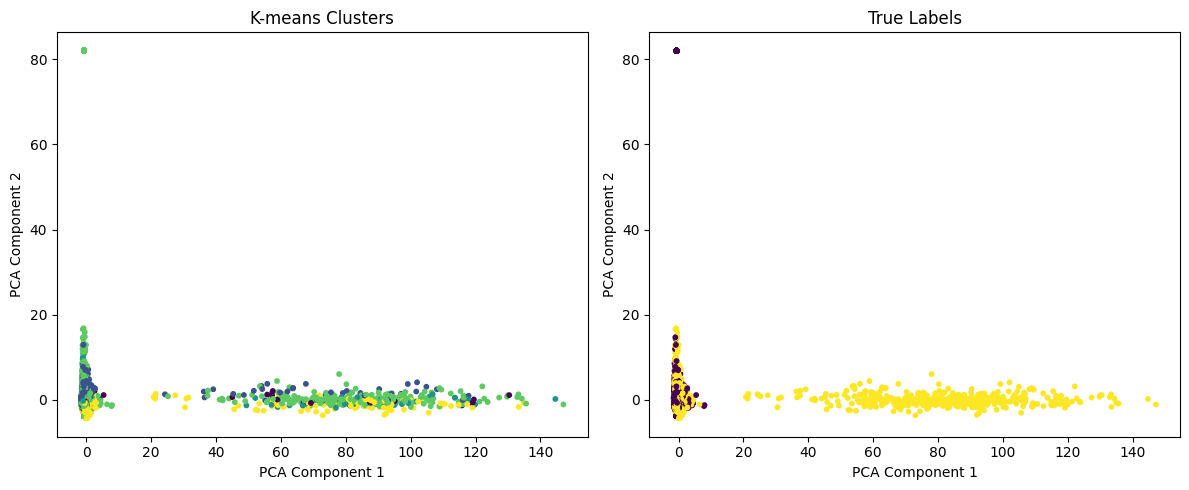

In [34]:

vectorizer = joblib.load(VEC_PATH)
training_vectors = vectorizer.transform(df_train_cleaned['Text'])
terms = vectorizer.get_feature_names_out()

k = 5
n_init = 10 #number of time the k-means algorithm will be run with different centroid seeds

#a) apply k-means to the training data with k=5 clusters
kmeans_model = clustering.KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=n_init)

#apply model to training data
kmeans_model.fit(training_vectors)

order_centroids = kmeans_model.cluster_centers_.argsort()[:, ::-1]

with open("kmeans_clusters.txt", "w", encoding="utf-8") as f:
    for i in range(k):
        f.write(f"Cluster {i}:\n")
        for ind in order_centroids[i, :10]:  # top 10 terms per cluster
            f.write(f" {terms[ind]}\n")
        f.write("\n")

#b) Inspect 3 documents closest to each centroid, and afterwards, assign semantic labels to each cluster 

distances = kmeans_model.transform(training_vectors)

for i in range(k):
    assigned_idxs = np.where(kmeans_model.labels_ == i)[0]
    closest_idxs = assigned_idxs[np.argsort(distances[assigned_idxs, i])[:3]]
    print(f"\nCluster {i} closest documents:")
    for idx in closest_idxs:
        print(f" Document index: {idx}, Distance: {distances[idx, i]:.4f}")
        print(f" Text: {df_train_cleaned.iloc[idx]['Text']}\n")
        #falta aqui colocar a label BERNARDOOO

#c) Visualize clusters in 2D using PCA. Create two plots: one colored by cluster assignment, one by true label.

X = training_vectors.toarray()
y = df_train_cleaned['Label'].values

#Standardize the data before PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#Não sei se o X_scaled está bem, o gráfico fica mesmo estranho 

#
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_model.labels_, cmap='viridis', s=10)
plt.title('K-means Clusters')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_train_cleaned['Label'], cmap='viridis', s=10)
plt.title('True Labels')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.tight_layout()
plt.show()
    




Aqui ficarao por ordem os snippets que fizemos para debbug

In [ ]:

    #Debugging functions for TF-IDF matrices

def print_tfidf_summary(vectors):
    n_docs, n_feats = vectors.shape
    nnz = vectors.nnz
    density = nnz / (n_docs * n_feats)
    print(f"shape: {n_docs} x {n_feats}")
    print(f"non-zeros: {nnz}  density: {density:.4%}")

def top_features_for_doc(vectors, feature_names, doc_idx=0, top_n=10):
    row = vectors.getrow(doc_idx).tocoo()
    if row.nnz == 0:
        print(f"doc {doc_idx}: no non-zero features")
        return
    idx = np.argsort(row.data)[::-1][:top_n]
    terms = [feature_names[row.col[i]] for i in idx]
    scores = row.data[idx]
    print(f"Top {top_n} features for doc {doc_idx}:")
    for t, s in zip(terms, scores):
        print(f"  {t}: {s:.4f}")

def top_features_global(vectors, feature_names, top_n=30, by="mean"):
    # by="mean" or "sum"
    if by == "mean":
        vals = np.asarray(vectors.mean(axis=0)).ravel()
    else:
        vals = np.asarray(vectors.sum(axis=0)).ravel()
    top_idx = np.argsort(vals)[::-1][:top_n]
    print(f"Top {top_n} features by {by}:")
    for i in top_idx:
        print(f"  {feature_names[i]}: {vals[i]:.6f}")

def as_dataframe(vectors, feature_names, max_cells=1e9):
    # Convert only if not too large
    n_docs, n_feats = vectors.shape
    if n_docs * n_feats > max_cells:
        raise MemoryError("matrix too large to convert to dense DataFrame")
    return pd.DataFrame(vectors.toarray(), columns=feature_names)


In [ ]:
# usage examples Debugging
print_tfidf_summary(training_vectors)
top_features_for_doc(training_vectors, feature_names, doc_idx=0, top_n=15)
top_features_global(training_vectors, feature_names, top_n=40, by="mean")

In [ ]:
#Debugging
# --- Corpus-level term summary and prints ---
# compute sums, means and document frequencies for each feature
sums = np.asarray(training_vectors.sum(axis=0)).ravel()
means = np.asarray(training_vectors.mean(axis=0)).ravel()
df_counts = np.diff(training_vectors.tocsc().indptr)  # documents-per-term

summary = pd.DataFrame({
    'term': feature_names,
    'sum': sums,
    'mean': means,
    'df': df_counts
})
if hasattr(vectorizer, 'idf_'):
    summary['idf'] = vectorizer.idf_

# print top terms by different metrics
def print_top_terms(summary, by='sum', top_n=30):
    print(f"\nTop {top_n} terms by {by}:")
    top = summary.sort_values(by=by, ascending=False).head(top_n)
    print(top[['term', 'sum', 'mean', 'df'] + (['idf'] if 'idf' in top.columns else [])].to_string(index=False))

In [ ]:
#DEBUGGING show top terms
print_top_terms(summary, by='sum', top_n=30)
print_top_terms(summary, by='df', top_n=30)

# show sample cleaned texts for first 5 documents
#print('\nSample cleaned texts (first 5 rows):')
#for i in range(min(5, len(df_train))):
    #print(f"[{i}] ", df_train['Text'].iloc[i])

In [ ]:
# save summary CSV DEBUGGING
summary_out = 'tfidf_term_summary.csv'
summary.sort_values(by='sum', ascending=False).to_csv(summary_out, index=False)
print(f"\nSaved term summary to: {summary_out}")

In [ ]:


RESULTS_DIR = "cv_results"
# COLOCAR AQUI O CVS DE VALIDACAO
DATA_CSV = "Data_Set/val.csv"
X_SPARSE_PATH = os.path.join(RESULTS_DIR, "X_sparse.joblib")
VEC_PATH = "tfidf_vectorizer.joblib"
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
OUT_METRICS = os.path.join(RESULTS_DIR, "metrics_comparison.csv")

def load_features(texts):
    """
    texts: pd.Series or list-like of texts for which we need features.
    If a saved X_sparse.joblib exists, reuse it only if row counts match.
    Otherwise transform texts with the saved vectorizer (VEC_PATH).
    """
    if os.path.exists(X_SPARSE_PATH):
        X = joblib.load(X_SPARSE_PATH)
        if X.shape[0] == len(texts):
            print(f"Loaded X sparse from {X_SPARSE_PATH} (rows match: {X.shape[0]})")
            return X
        else:
            print(f"Saved X_sparse has {X.shape[0]} rows but {len(texts)} requested — rebuilding from vectorizer.")
    if os.path.exists(VEC_PATH):
        vec = joblib.load(VEC_PATH)
        X = vec.transform(pd.Series(texts).fillna('').astype(str))
        print(f"Transformed texts with loaded vectorizer {VEC_PATH}")
        return X
    raise FileNotFoundError("No X_sparse.joblib or tfidf_vectorizer.joblib found; run cv_search first.")

def load_data():
    df = pd.read_csv(DATA_CSV)
    if 'Label' not in df.columns:
        raise RuntimeError("CSV must contain 'Label' column")
    y = df['Label'].values
    return df, y

def load_estimators():
    files = [f for f in os.listdir(RESULTS_DIR) if f.endswith("_best_estimator.joblib")]
    files.sort()
    if not files:
        raise RuntimeError(f"No *_best_estimator.joblib files found in {RESULTS_DIR}")
    estimators = {}
    for f in files:
        name = f.replace("_best_estimator.joblib", "")
        estimators[name] = joblib.load(os.path.join(RESULTS_DIR, f))
    return estimators

    